# Reto 3 · Modelo de clustering K-Means

**Clustering the Star — Mercedes-Benz · III Malackathon 2026**

Partimos de la matriz de features del Reto 2 (1 fila por cliente, 13 features escaladas) y:

1. Ejecutamos K-Means para **k = 2 … 10**
2. Calculamos el **método del codo** (inercia) y el **Silhouette Score** de cada k
3. Comprobamos que la segmentación no esté sesgada por **país** ni sea fruto de la **inicialización**
4. Entrenamos el **modelo final** con el k elegido y vemos la **distribución de clientes por cluster**

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

from features import cargar_datos, construir_pipeline, ajustar_kmeans, K_FINAL, SEMILLA

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.float_format", "{:,.3f}".format)

df = cargar_datos()
pipe = construir_pipeline()
X = pipe.fit_transform(df)
clientes = pipe.named_steps["agregar"].transform(df)
pct_ch_total = (clientes["country_code"] == "CH").mean() * 100
print("Matriz:", X.shape, f"· clientes CH: {pct_ch_total:.1f} %")

Matriz: (173456, 13) · clientes CH: 66.2 %


## 1. Decisiones de método (y problemas que evitan)

| Riesgo | Qué pasaría | Cómo lo evitamos |
|---|---|---|
| Silhouette sobre 173.456 clientes | Coste O(n²): inviable en memoria y tiempo | Se calcula sobre **muestras aleatorias de 20.000 clientes**, repetido con 3 semillas; se reporta media y desviación |
| Inicialización aleatoria de K-Means | Resultados distintos en cada ejecución | `n_init=10` (se queda con la mejor de 10 inicializaciones) y `random_state` fijo; además se mide la estabilidad entre semillas (apartado 4) |
| Clusters que separan países | Segmentos que solo dicen "suizo / austriaco" | País fuera del modelo y poder adquisitivo + visitas al taller relativos al país (Reto 2). Se comprueba la mezcla de países por cluster |
| Clusters diminutos | Segmentos sin masa crítica para una campaña | Se vigila el tamaño del cluster más pequeño para cada k |

In [2]:
SEMILLAS_SIL = [0, 1, 2]
TAM_MUESTRA = 20_000
resultados, modelos = [], {}
for k in range(2, 11):
    t = time.time()
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(X)
    sils = [silhouette_score(X, km.labels_, sample_size=TAM_MUESTRA, random_state=s) for s in SEMILLAS_SIL]
    tam = np.bincount(km.labels_) / len(X) * 100
    pct_ch = pd.crosstab(km.labels_, clientes["country_code"], normalize="index")["CH"] * 100
    resultados.append({"k": k, "inercia": km.inertia_, "silhouette": np.mean(sils), "silhouette_std": np.std(sils),
                       "cluster_min_%": tam.min(), "CH_min_%": pct_ch.min(), "CH_max_%": pct_ch.max(),
                       "segundos": time.time() - t})
    modelos[k] = km
res = pd.DataFrame(resultados).set_index("k")
res["caída_inercia_%"] = -res["inercia"].pct_change() * 100
res

,inercia,silhouette,silhouette_std,cluster_min_%,CH_min_%,CH_max_%,segundos,caída_inercia_%
k,,,,,,,,
2,"2,015,308.970",0.102,0.000,49.440,63.556,68.828,10.494,NaN
3,"1,862,792.932",0.096,0.001,17.588,62.179,69.008,10.417,7.568
4,"1,723,200.216",0.108,0.000,16.033,54.565,71.544,10.660,7.494
5,"1,589,114.507",0.129,0.000,8.745,54.565,72.368,10.865,7.781
6,"1,497,676.686",0.123,0.000,8.723,54.971,73.061,10.817,5.754
7,"1,426,848.612",0.122,0.000,7.720,54.818,85.531,10.949,4.729
8,"1,370,832.456",0.123,0.000,7.078,54.885,85.504,11.602,3.926
9,"1,328,842.749",0.111,0.000,6.684,54.963,85.347,11.513,3.063
10,"1,297,801.320",0.110,0.001,3.461,55.302,85.553,12.173,2.336


## 2. Método del codo y Silhouette

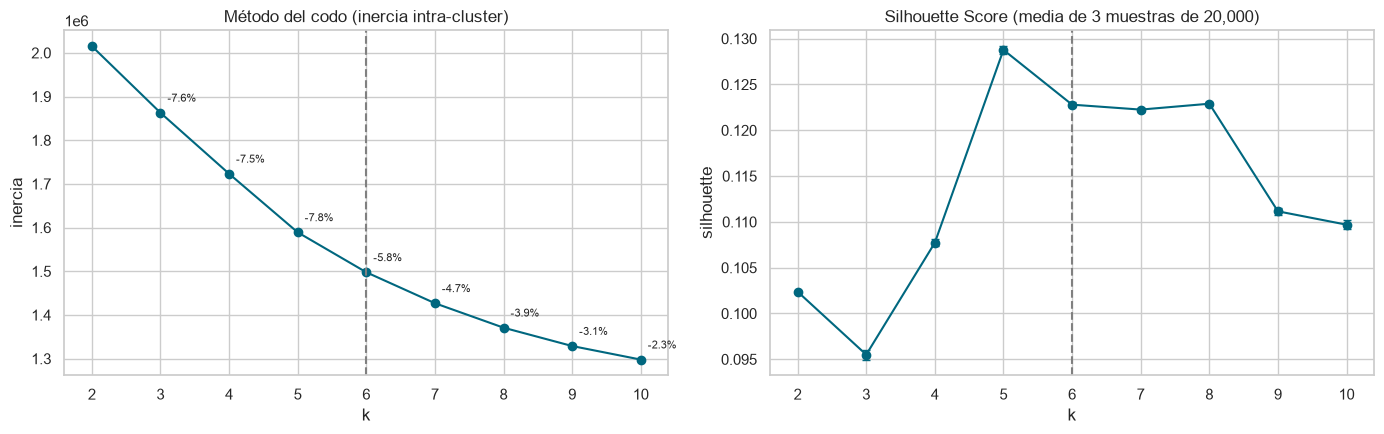

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(res.index, res["inercia"], "o-", color="#00677F")
axes[0].axvline(K_FINAL, ls="--", color="grey")
for k, v in res["caída_inercia_%"].dropna().items():
    axes[0].annotate(f"-{v:.1f}%", (k, res.loc[k, "inercia"]), textcoords="offset points", xytext=(5, 8), fontsize=8)
axes[0].set(title="Método del codo (inercia intra-cluster)", xlabel="k", ylabel="inercia")
axes[1].errorbar(res.index, res["silhouette"], yerr=res["silhouette_std"], fmt="o-", color="#00677F", capsize=3)
axes[1].axvline(K_FINAL, ls="--", color="grey")
axes[1].set(title=f"Silhouette Score (media de {len(SEMILLAS_SIL)} muestras de {TAM_MUESTRA:,})", xlabel="k", ylabel="silhouette")
plt.tight_layout()
plt.show()

**Lectura:**
- **Codo**: la inercia baja de forma suave. Las mayores caídas relativas llegan hasta k = 5 (≈ 7-8 % por
  cluster añadido). A partir de k = 6 cada cluster extra aporta menos (5,8 % → 4,7 % → 3,9 %…). El codo está en la
  zona **k = 5-6**.
- **Silhouette**: el máximo está en **k = 5 (0,129)**, con k = 6-8 prácticamente empatados (≈ 0,12) y una caída
  clara a partir de k = 9. La desviación entre muestras es mínima (< 0,001), así que el muestreo no distorsiona la métrica.
- **¿Es bajo un silhouette de 0,12?** Sí, y es esperable: los clientes no forman grupos naturalmente separados,
  sino un **continuo** (edad, antigüedad, gama…). K-Means "corta" ese continuo en zonas homogéneas. Lo importante
  es que los segmentos sean **distintos, estables y accionables**, que es lo que se comprueba a continuación.

## 3. ¿Algún cluster es "un país"?

Si la segmentación estuviera sesgada por país, algún cluster tendría casi todo suizos o casi todo austriacos.
Referencia: el 66 % de los clientes son suizos.

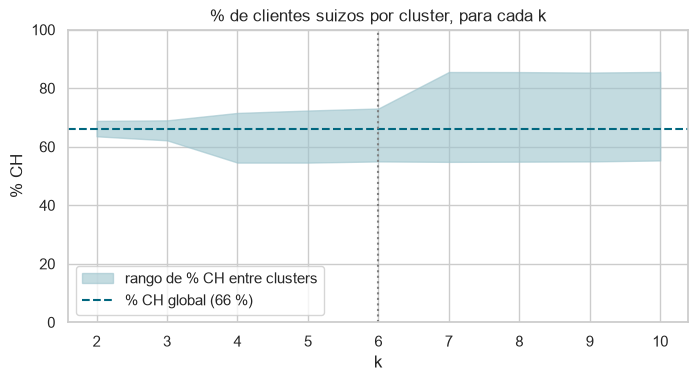

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.fill_between(res.index, res["CH_min_%"], res["CH_max_%"], color="#9cc3cc", alpha=.6, label="rango de % CH entre clusters")
ax.axhline(pct_ch_total, color="#00677F", ls="--", label=f"% CH global ({pct_ch_total:.0f} %)")
ax.axvline(K_FINAL, ls=":", color="grey")
ax.set(title="% de clientes suizos por cluster, para cada k", xlabel="k", ylabel="% CH", ylim=(0, 100))
ax.legend(loc="lower left")
plt.show()

Hasta **k = 6** todos los clusters tienen entre un ~55 % y un ~73 % de clientes suizos: **ningún segmento es un
país**. A partir de k = 7 aparece un cluster de **leasing activo** con un ~86 % de suizos. No es un error de datos:
el leasing está mucho más extendido en Suiza (29 % de clientes frente a 13 % en Austria), y se decidió mantenerlo
como comportamiento real. Aun así, es otro motivo para no ir más allá de k = 6.

**Problema detectado y corregido durante este reto**: en una primera versión, las visitas al taller se usaban en
valor absoluto y generaban un cluster con un 81-86 % de suizos. El motivo era una diferencia de **registro** entre
países (52 % de austriacos con 0 visitas frente a 23 % de suizos, con coches de la misma antigüedad). Se corrigió en
el pipeline del Reto 2 expresando las visitas como percentil dentro del país.

## 4. Elección de k

| Criterio | k = 5 | k = 6 |
|---|---|---|
| Silhouette | **0,129** (máximo) | 0,123 |
| Codo | Última caída grande | Inicio de la meseta |
| Mezcla de países | OK | OK |
| Cluster más pequeño | 8,7 % | 8,7 % |
| Valor de negocio | 5 perfiles | **+ segmento "no contactables"** y separación de los clientes muy activos en taller |

**Elegimos k = 6.** La diferencia de silhouette con k = 5 es mínima (0,006, dentro de la zona plana de 5-8), y a
cambio k = 6 separa dos grupos con un **uso comercial directo**:
- **clientes con pocos consentimientos**: necesitan una estrategia de recaptación de permisos antes de cualquier campaña;
- **clientes muy fieles al taller**: el público natural de los planes de mantenimiento.

Con k = 7 o más el silhouette no mejora, aparecen clusters dominados por un país y la segmentación se vuelve
difícil de gestionar para un equipo de marketing.

### Estabilidad frente a la inicialización

Entrenamos k = 6 con 5 semillas distintas y comparamos las asignaciones con el **Adjusted Rand Index**
(1 = asignaciones idénticas salvo el nombre del cluster).

In [5]:
etiquetas = {s: KMeans(n_clusters=K_FINAL, n_init=10, random_state=s).fit_predict(X) for s in [42, 0, 1, 2, 3]}
ari = pd.DataFrame({a: {b: adjusted_rand_score(etiquetas[a], etiquetas[b]) for b in etiquetas} for a in etiquetas})
print(f"ARI medio entre semillas: {ari.values[np.triu_indices(5, 1)].mean():.3f}")
ari

ARI medio entre semillas: 0.996


,42,0,1,2,3
42,1.000,0.996,0.995,0.999,0.998
0,0.996,1.000,0.996,0.996,0.994
1,0.995,0.996,1.000,0.995,0.993
2,0.999,0.996,0.995,1.000,0.999
3,0.998,0.994,0.993,0.999,1.000


## 5. Modelo final (k = 6) y distribución de clientes

In [6]:
km = ajustar_kmeans(X)
clientes["cluster"] = km.labels_
dist = clientes["cluster"].value_counts().sort_index().to_frame("clientes")
dist["%"] = dist["clientes"] / len(clientes) * 100
dist

,clientes,%
cluster,,
0,21366,12.318
1,45174,26.043
2,21935,12.646
3,15130,8.723
4,44976,25.929
5,24875,14.341


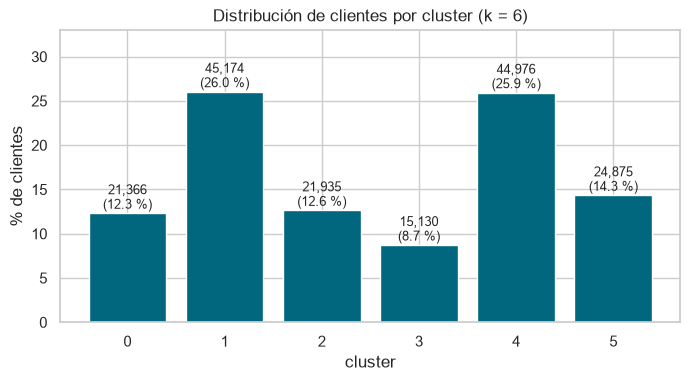

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(dist.index.astype(str), dist["%"], color="#00677F")
for i, (n, p) in enumerate(zip(dist["clientes"], dist["%"])):
    ax.text(i, p + 0.5, f"{n:,}\n({p:.1f} %)", ha="center", fontsize=9)
ax.set(title="Distribución de clientes por cluster (k = 6)", xlabel="cluster", ylabel="% de clientes", ylim=(0, dist["%"].max() + 7))
plt.show()

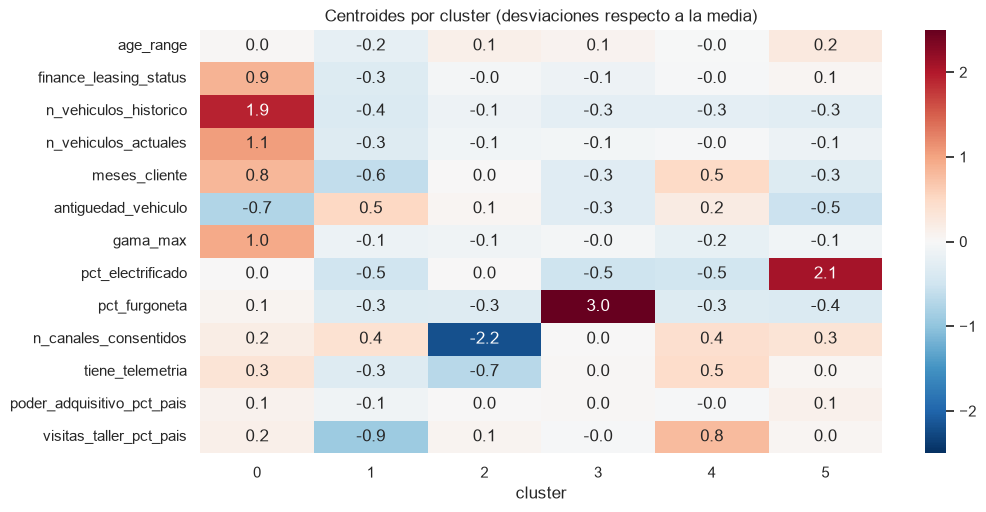

In [8]:
# Centroides en unidades estandarizadas: qué distingue a cada cluster
centroides = pd.DataFrame(km.cluster_centers_, columns=X.columns)
plt.figure(figsize=(11, 5.5))
sns.heatmap(centroides.T, cmap="RdBu_r", center=0, vmin=-2.5, vmax=2.5, annot=True, fmt=".1f")
plt.title("Centroides por cluster (desviaciones respecto a la media)")
plt.xlabel("cluster")
plt.show()

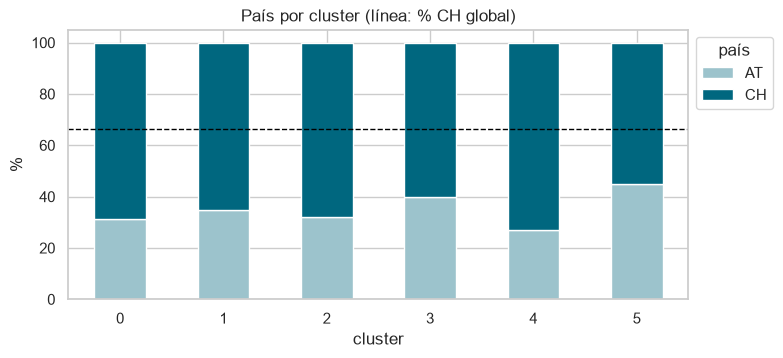

In [9]:
# Mezcla de países en el modelo final
mezcla = pd.crosstab(clientes["cluster"], clientes["country_code"], normalize="index").mul(100)
mezcla.plot.bar(stacked=True, figsize=(8, 3.5), color=["#9cc3cc", "#00677F"], rot=0)
plt.axhline(pct_ch_total, color="black", ls="--", lw=1)
plt.title("País por cluster (línea: % CH global)")
plt.ylabel("%")
plt.legend(title="país", bbox_to_anchor=(1, 1))
plt.show()

### Silhouette por cluster

Un silhouette medio bajo puede esconder clusters bien definidos y otros difusos. Lo calculamos por cluster
sobre una muestra.

In [10]:
muestra = np.random.default_rng(0).choice(len(X), TAM_MUESTRA, replace=False)
sil_ind = silhouette_samples(X.iloc[muestra], km.labels_[muestra])
sil_cluster = pd.Series(sil_ind).groupby(km.labels_[muestra]).agg(["mean", lambda s: (s < 0).mean() * 100])
sil_cluster.columns = ["silhouette medio", "% clientes con silhouette < 0"]
sil_cluster

,silhouette medio,% clientes con silhouette < 0
0,0.046,40.328
1,0.102,10.054
2,0.073,16.895
3,0.203,1.230
4,0.168,0.000
5,0.145,1.669


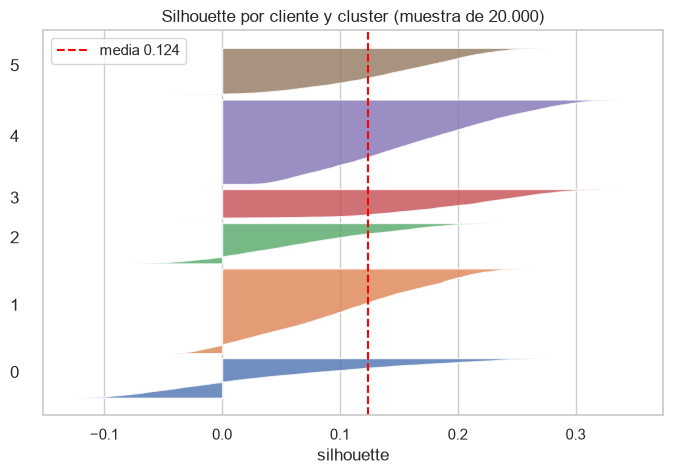

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
y = 0
for c in range(K_FINAL):
    v = np.sort(sil_ind[km.labels_[muestra] == c])
    ax.fill_betweenx(np.arange(y, y + len(v)), 0, v, alpha=.8)
    ax.text(-0.18, y + len(v) / 2, str(c))
    y += len(v) + 300
ax.axvline(sil_ind.mean(), color="red", ls="--", label=f"media {sil_ind.mean():.3f}")
ax.set(title="Silhouette por cliente y cluster (muestra de 20.000)", xlabel="silhouette", yticks=[])
ax.legend()
plt.show()

**Lectura por cluster:**
- Los clusters **3, 4 y 5** son los más compactos (silhouette 0,15-0,20, casi sin clientes mal asignados).
- Los clusters **1 y 2** son aceptables.
- El **cluster 0** es el más difuso: silhouette 0,05 y un **40 % de clientes con silhouette negativo**, es decir,
  en la frontera con otros clusters. Es el grupo de clientes **multi-vehículo / leasing / gama alta**: agrupa
  perfiles de alto valor pero heterogéneos (desde familias con dos coches hasta pequeñas flotas). En el Reto 4 se
  perfila con cuidado y se recomienda **sub-segmentarlo** si se quiere afinar una campaña sobre él.

## 6. Conclusiones

- Se evaluó K-Means para k = 2 … 10 con codo y silhouette. Se eligió **k = 6** por combinar métricas en la zona
  óptima (codo en 5-6, silhouette ≈ 0,12-0,13) con **mayor valor de negocio** que k = 5.
- Los 6 clusters tienen masa crítica (el más pequeño ≈ 9 % de los clientes, más de 15.000) y **ninguno está
  dominado por un país**.
- La segmentación es **muy estable** frente a la inicialización: ARI medio de **0,996** entre 5 semillas.
- El cluster 0 (multi-vehículo / leasing) es el menos cohesionado (silhouette 0,05): segmento de alto valor pero
  heterogéneo.
- Problemas detectados y resueltos: coste del silhouette (muestreo repetido), sesgo de registro de las visitas
  al taller entre países (percentil por país) y riesgo de clusters "país" con k ≥ 7 (se descarta).
- En el Reto 4 se interpreta cada cluster en lenguaje de negocio y se le pone nombre.